In [5]:
from common import *

os.makedirs('figures/replex')

In [6]:
system = '7ez0'
ff = 'mMg_tip3p'
rep = 0
nrep = 8

cv_dmx = np.stack([
    read_plumed(PROJECT_DIR / f'replex/{system}/{ff}/replicate{rep}/rep{i:02d}/bias.COLVAR.{i}').drop_duplicates('time').assign(rep=i)
    for i in range(nrep)
])
cv = demux(cv_dmx, repindex_file=PROJECT_DIR / f'replex/{system}/{ff}/replicate{rep}/rep00/bias_index.xvg')

nox_dmx = np.stack([
    read_plumed(PROJECT_DIR / f'replex/{system}/{ff}/replicate{rep}/rep{i:02d}/cv.COLVAR.{i}').drop_duplicates('time').assign(rep=i)
    for i in range(nrep)
])
nox_dmx[:, :, 1:-2:3] *= 1.039661
nox_dmx[:, :, 2:-2:3] *= 1.039661
nox = demux(nox_dmx, repindex_file=PROJECT_DIR / f'replex/{system}/{ff}/replicate{rep}/rep00/bias_index.xvg')

In [7]:
d_mg_op_dmx = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'replex/{system}/{ff}/replicate{rep}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])
d_op_mg_dmx = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'replex/{system}/{ff}/replicate{rep}/rep{i:02d}/dist_O_Phosphate_MG.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])

d_mg_op = demux(d_mg_op_dmx, repindex_file=PROJECT_DIR / f'replex/{system}/{ff}/replicate{rep}/rep00/bias_index.xvg')
d_op_mg = demux(d_op_mg_dmx, repindex_file=PROJECT_DIR / f'replex/{system}/{ff}/replicate{rep}/rep00/bias_index.xvg')


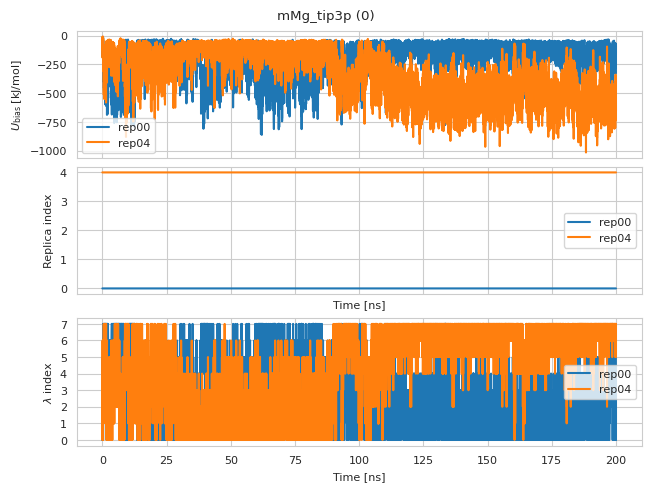

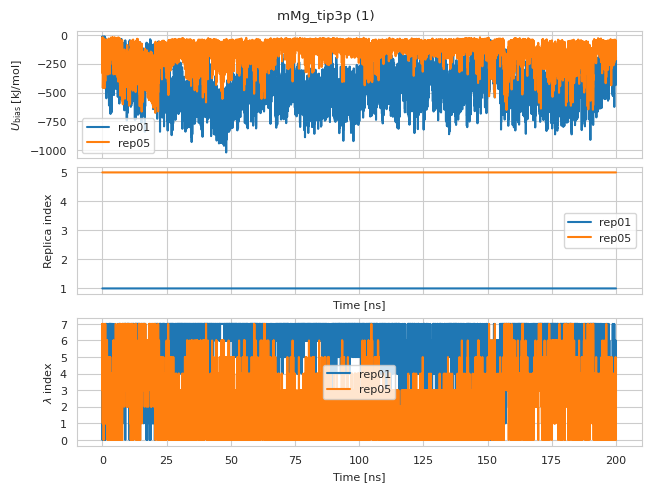

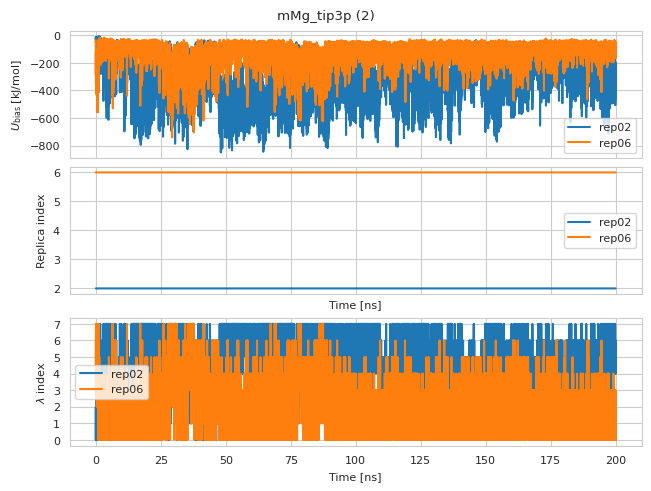

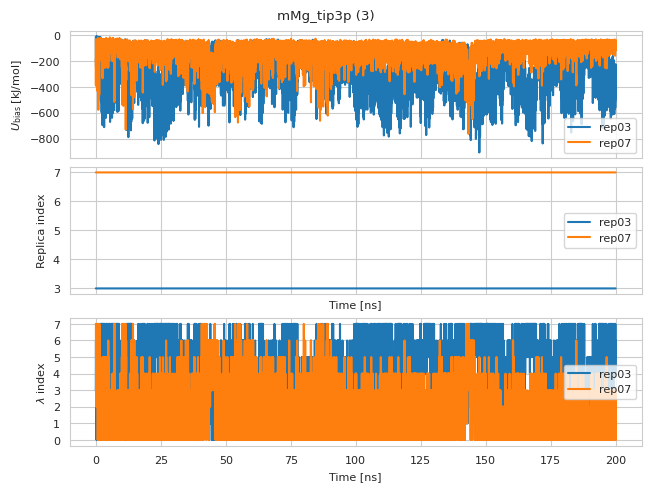

In [8]:
figs = []
for n in range(4):
    fig, axarr = plt.subplots(nrows=3, sharex=True)
    fig.suptitle(f"{ff} ({n})")
    for i in range(n, nrep, 4):
        ax = axarr[0]
        ax.plot(cv_dmx[i, :, 0]/1000, cv_dmx[i, :, 1], label=f'rep{i:02d}')
        ax.set_ylabel("$U_\mathrm{bias}$ [kJ/mol]")
        #[ax.axvline(r, color='gray', alpha=0.5) for r in restarts]
        ax.legend()
        ax = axarr[1]
        ax.plot(cv_dmx[i, :, 0]/1000, cv_dmx[i, :, -1], label=f'rep{i:02d}')
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_ylabel("Replica index")
        ax.set_xlabel("Time [ns]")
        #[ax.axvline(r, color='gray', alpha=0.5) for r in restarts]
        ax.legend()
        ax = axarr[2]
        ax.plot(cv_dmx[i, :, 0]/1000, cv_dmx[i, :, -2], label=f'rep{i:02d}')
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_ylabel("$λ$ index")
        ax.set_xlabel("Time [ns]")
        #[ax.axvline(r, color='gray', alpha=0.5) for r in restarts]
        ax.legend()
    figs.append(fig)

with PdfPages(f'figures/replex/bias_{system}_{ff}.pdf') as pdf:
    for fig in figs:
        pdf.savefig(fig, bbox_inches='tight') 

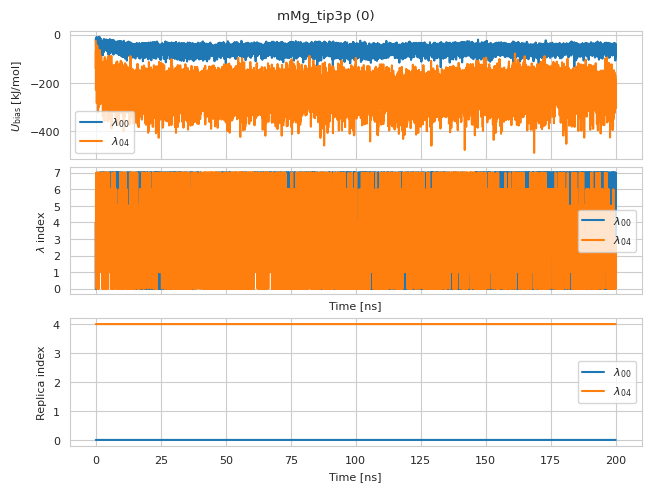

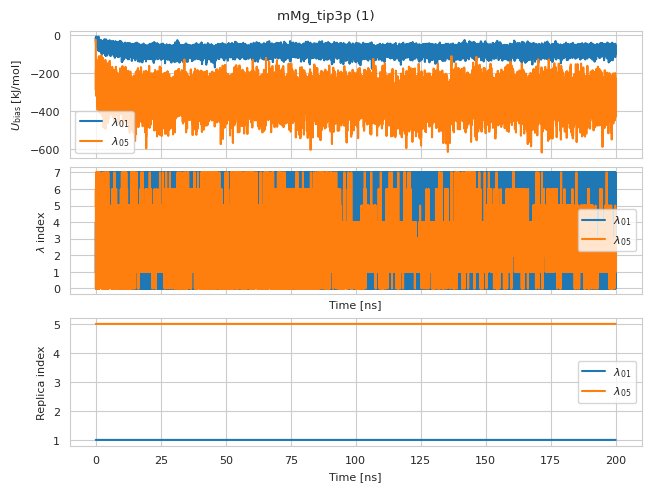

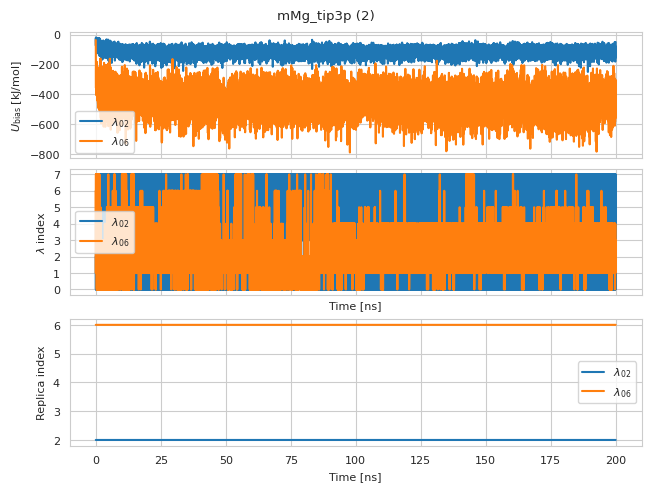

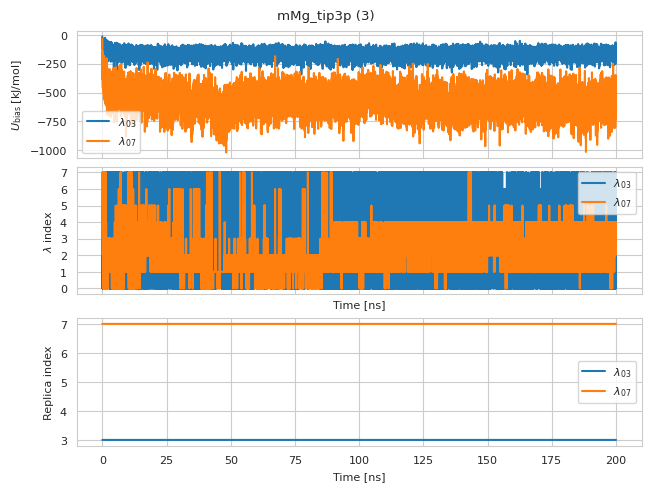

In [9]:
figs = []
for n in range(4):
    fig, axarr = plt.subplots(nrows=3, sharex=True)
    fig.suptitle(f"{ff} ({n})")
    for i in range(n, nrep, 4):
        ax = axarr[0]
        ax.plot(cv[i, :, 0]/1000, cv[i, :, 1], label=f'$λ_{{{i:02d}}}$')
        ax.set_ylabel("$U_\mathrm{bias}$ [kJ/mol]")
        ax.legend()
        ax = axarr[1]
        ax.plot(cv[i, :, 0]/1000, cv[i, :, -1], label=f'$λ_{{{i:02d}}}$')
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_ylabel("$λ$ index")
        ax.set_xlabel("Time [ns]")
        ax.legend()
        ax = axarr[2]
        ax.plot(cv[i, :, 0]/1000, cv[i, :, -2], label=f'$λ_{{{i:02d}}}$')
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_ylabel("Replica index")
        ax.set_xlabel("Time [ns]")
        ax.legend()
    figs.append(fig)

with PdfPages(f'figures/replex/bias_{system}_{ff}.pdf') as pdf:
    for fig in figs:
        pdf.savefig(fig, bbox_inches='tight') 

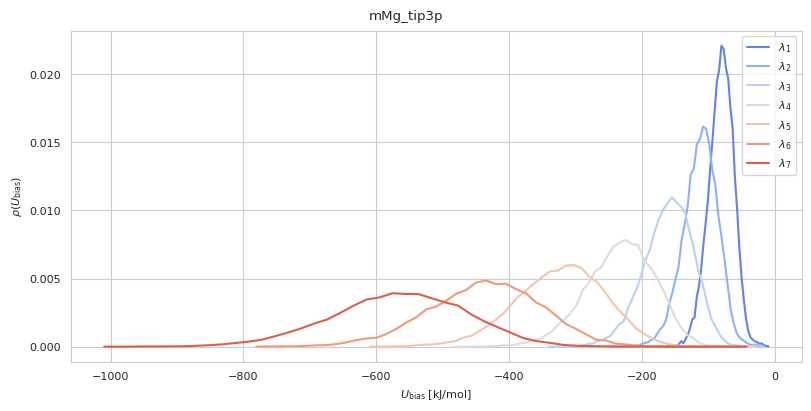

In [10]:
# Bias distribution as a function of λ
fig, ax = plt.subplots(figsize=(8, 4))
for i in range(1, nrep):
    ρ_u, bins = np.histogram(cv[i, :, 1], bins=50, density=True)
    u_range = edges_to_range(bins)
    ax.plot(u_range, ρ_u, label=f'$λ_{{{i}}}$', color=plt.cm.coolwarm(i/nrep))
ax.legend()
ax.set_xlabel('$U_\mathrm{bias}$ [kJ/mol]')
ax.set_ylabel('$ρ(U_\mathrm{bias}$)')
fig.suptitle(ff)
plt.savefig(f'figures/replex/bias_dist_{system}_{ff}.pdf')

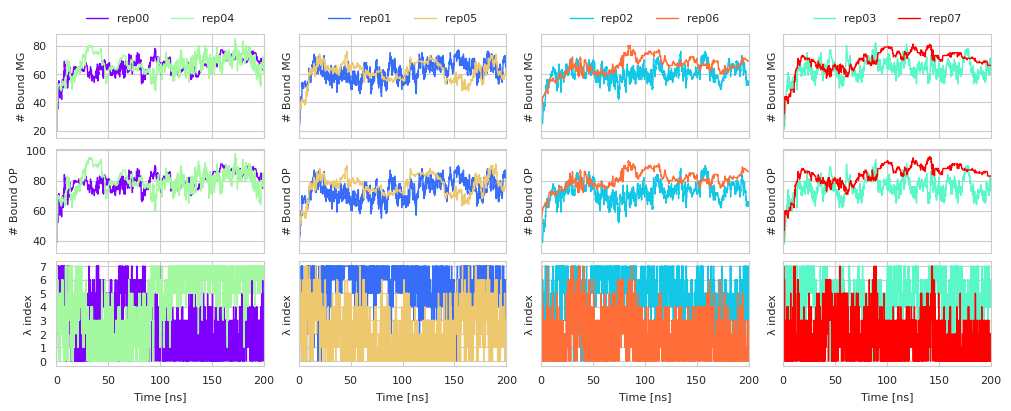

In [11]:
fig, axarr = plt.subplots(nrows=3, ncols=4, sharex=True, sharey='row', figsize=(10, 4))
#fig.suptitle(ff)
for i in range(nrep):
    n = i % 4
    ax = axarr[0, n]
    ax.plot(d_mg_op_dmx[i, :, 0] / 1000, (d_mg_op_dmx[i, :, 2:] < 0.25).sum(axis=-1), label=f'rep{i:02d}', color=plt.cm.rainbow(i/(nrep-1)), lw=1)
    ax.set_ylabel('# Bound MG')
    ax.legend(loc='lower center', ncols=2, bbox_to_anchor=(0.5, 1), frameon=False)
    ax = axarr[1, n]
    ax.plot(d_op_mg_dmx[i, :, 0] / 1000, (d_op_mg_dmx[i, :, 2:] < 0.25).sum(axis=-1), label=f'rep{i:02d}', color=plt.cm.rainbow(i/(nrep-1)), lw=1)
    ax.set_ylabel('# Bound OP')
    ax = axarr[2, n]
    ax.plot(cv_dmx[i, ::10, 0] / 1000, cv_dmx[i, ::10, -2], label=f'rep{i:02d}', color=plt.cm.rainbow(i/(nrep-1)), lw=1)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_ylabel('λ index')
    ax.set_xlabel("Time [ns]")
    ax.set_xlim(0, cv_dmx[i, :, 0].max() / 1000)

plt.savefig(f'figures/replex/bound_mg_replica_{system}_{ff}.pdf')

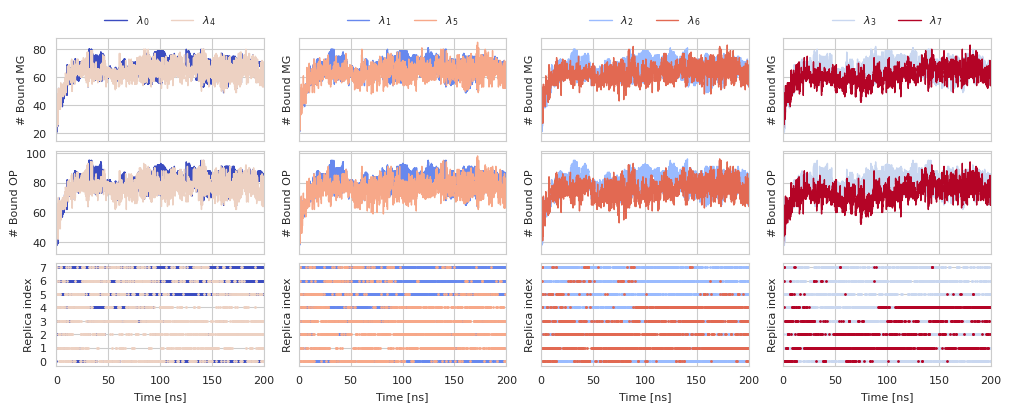

In [12]:
fig, axarr = plt.subplots(nrows=3, ncols=4, sharex=True, sharey='row', figsize=(10, 4))
#fig.suptitle(ff)
for n in range(4):
    for i in range(n, nrep, 4):
        ax = axarr[0, n]
        ax.plot(d_mg_op[i, :, 0] / 1000, (d_mg_op[i, :, 2:] < 0.25).sum(axis=-1), label=f'$λ_{{{i}}}$', color=plt.cm.coolwarm(i/(nrep-1)), lw=1)
        ax.set_ylabel('# Bound MG')
        ax.legend(loc='lower center', ncols=2, bbox_to_anchor=(0.5, 1), frameon=False)
        ax = axarr[1, n]
        ax.plot(d_op_mg[i, :, 0] / 1000, (d_op_mg[i, :, 2:] < 0.25).sum(axis=-1), label=f'$λ_{{{i}}}$', color=plt.cm.coolwarm(i/(nrep-1)), lw=1)
        ax.set_ylabel('# Bound OP')
        ax = axarr[2, n]
        ax.scatter(cv[i, ::10, 0] / 1000, cv[i, ::10, -1], label=f'$λ_{{{i}}}$', color=plt.cm.coolwarm(i/(nrep-1)), s=1)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_ylabel('Replica index')
        ax.set_xlabel("Time [ns]")
        ax.set_xlim(0, cv_dmx[i, :, 0].max() / 1000)

plt.savefig(f'figures/replex/bound_mg_lambda_{system}_{ff}.pdf')

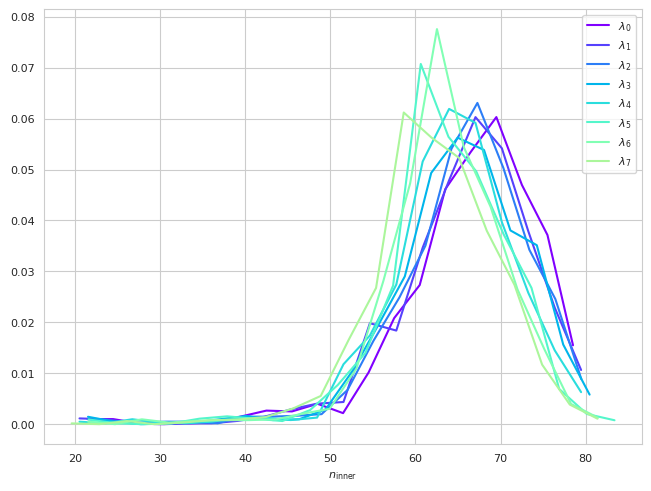

In [13]:
fig, ax = plt.subplots()
for i in range(nrep):
    hist, n_edges = np.histogram((d_mg_op[i, :, 1:] < 0.28).sum(axis=-1), density=True, bins=20)
    ax.plot(edges_to_range(n_edges), hist, color=plt.cm.rainbow(i/12.0), label=f"$λ_{{{i}}}$")
ax.legend()
ax.set_xlabel('$n_\mathrm{inner}$')
plt.savefig(f'figures/replex/n_inner_dist_{system}_{ff}.pdf')

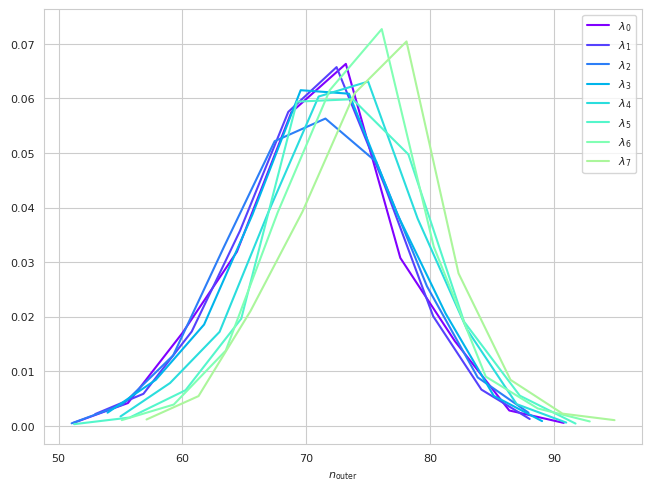

In [14]:
fig, ax = plt.subplots()
for i in range(nrep):
    hist, n_edges = np.histogram(((d_mg_op[i, :, 1:] > 0.28)*(d_mg_op[i, :, 1:] < 0.5)).sum(axis=-1), density=True, bins=10)
    ax.plot(edges_to_range(n_edges), hist, color=plt.cm.rainbow(i/12.0), label=f"$λ_{{{i}}}$")
ax.legend()
ax.set_xlabel('$n_\mathrm{outer}$')
plt.savefig(f'figures/replex/n_outer_dist_{system}_{ff}.pdf')


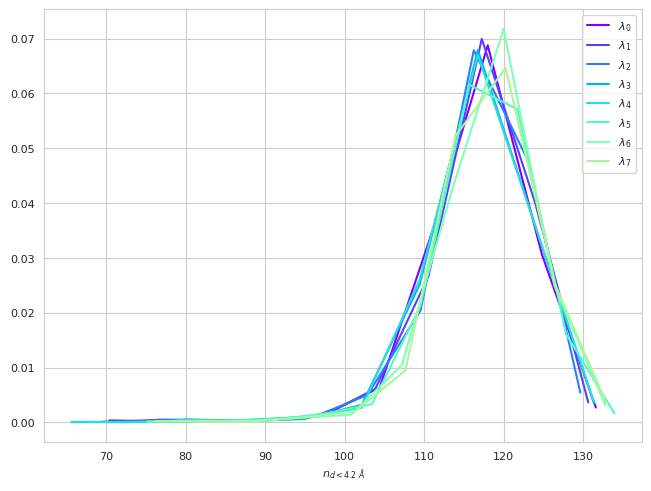

In [15]:
fig, ax = plt.subplots()
for i in range(nrep):
    hist, n_edges = np.histogram((d_mg_op[i, :, 1:] < 0.42).sum(axis=-1), density=True, bins=10)
    ax.plot(edges_to_range(n_edges), hist, color=plt.cm.rainbow(i/12.0), label=f"$λ_{{{i}}}$")
ax.legend()
ax.set_xlabel('$n_{d<4.2~Å}$')
plt.savefig(f'figures/replex/n_tot_dist_{system}_{ff}.pdf')

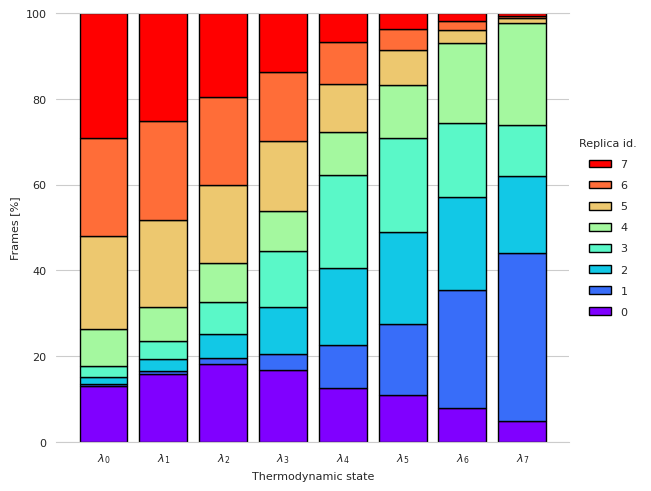

In [16]:
# Composition of each temp
fig, ax = plt.subplots()
bottom = np.zeros(nrep)
n_frames = cv_dmx.shape[1]

for k in range(nrep):
    x, counts = np.unique(cv_dmx[k, :, -2].astype(int), return_counts=True)
    ax.bar(x, counts/n_frames*100, bottom=bottom[x], color=plt.cm.rainbow(k/(nrep-1)), label=f'{k}', edgecolor='black')
    bottom[x] += counts/n_frames*100
ax.legend(title='Replica id.', loc='center left', bbox_to_anchor=(1, 0.5), frameon=False, reverse=True, labelspacing=1)
ax.set_xlabel("Thermodynamic state")
ax.set_xticks(range(nrep), [f"$λ_{{{k}}}$" for k in range(nrep)])
ax.set_ylabel("Frames [%]")
ax.set_ylim(0, 100)
ax.spines[['left', 'right']].set_visible(False)
plt.savefig(f'figures/replex/replica_occupancy_{system}_{ff}.pdf')

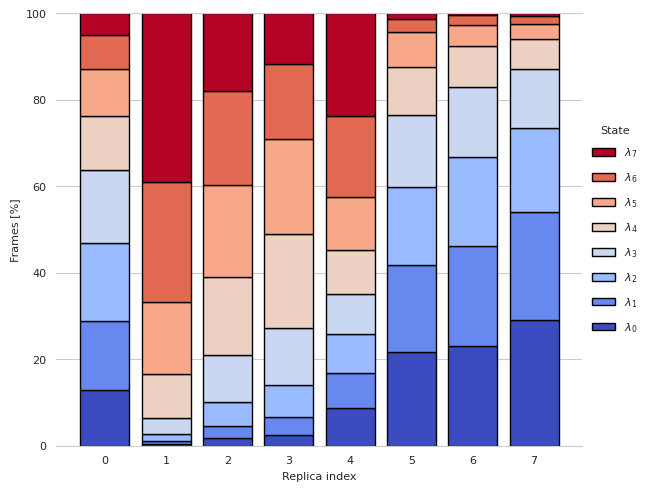

In [17]:
# Composition of each temp
fig, ax = plt.subplots()
bottom = np.zeros(nrep)
n_frames = cv_dmx.shape[1]

for k in range(nrep):
    x, counts = np.unique(cv[k, :, -1].astype(int), return_counts=True)
    ax.bar(x, counts/n_frames*100, bottom=bottom[x], color=plt.cm.coolwarm(k/(nrep-1)), label=f'$λ_{{{k}}}$', edgecolor='black')
    bottom[x] += counts/n_frames*100
ax.legend(title='State', loc='center left', bbox_to_anchor=(1, 0.5), frameon=False, reverse=True, labelspacing=1)
ax.set_xlabel("Replica index")
ax.set_xticks(range(nrep))
ax.set_ylabel("Frames [%]")
ax.set_ylim(0, 100)
ax.spines[['left', 'right']].set_visible(False)
plt.savefig(f'figures/replex/lambda_occupancy_{system}_{ff}.pdf')

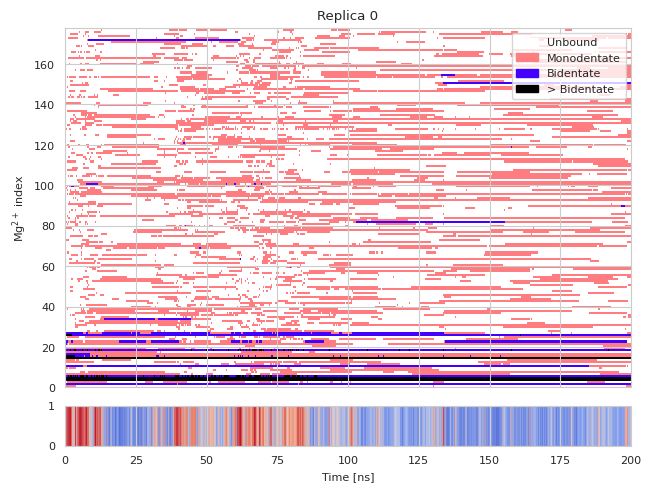

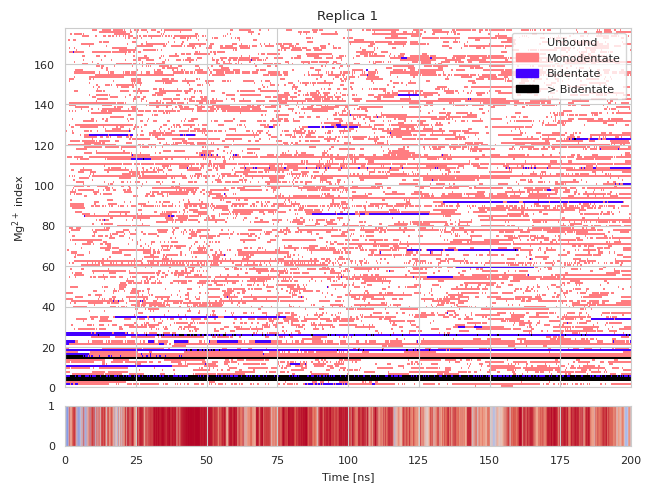

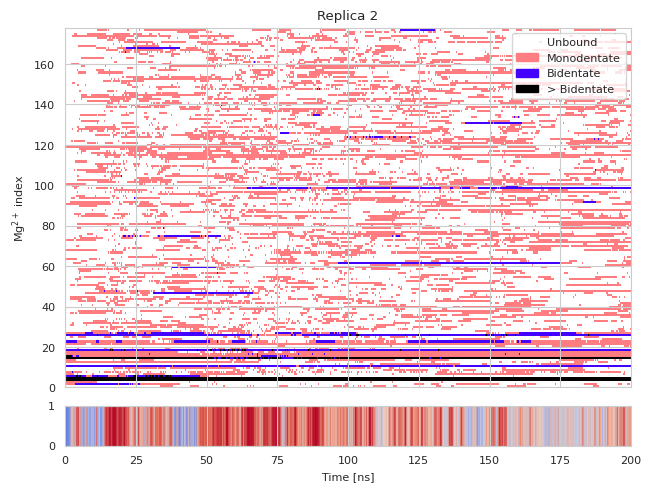

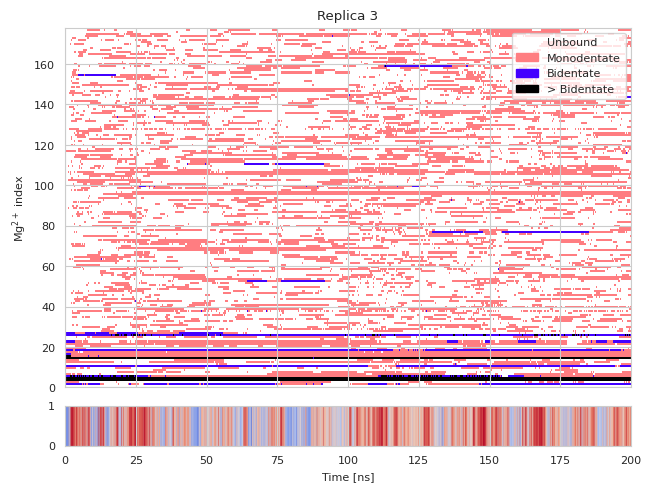

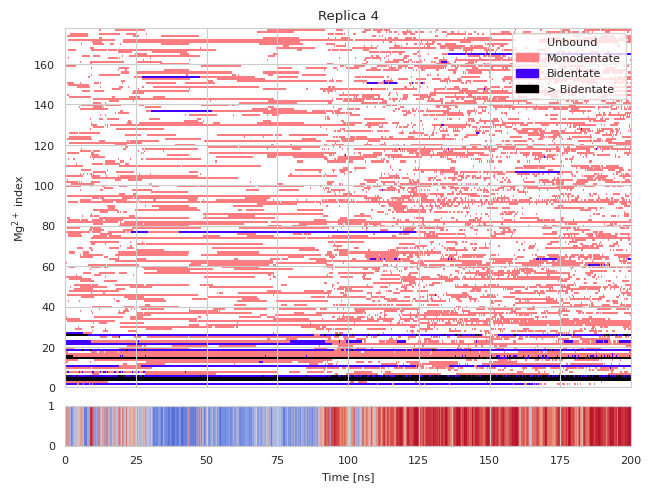

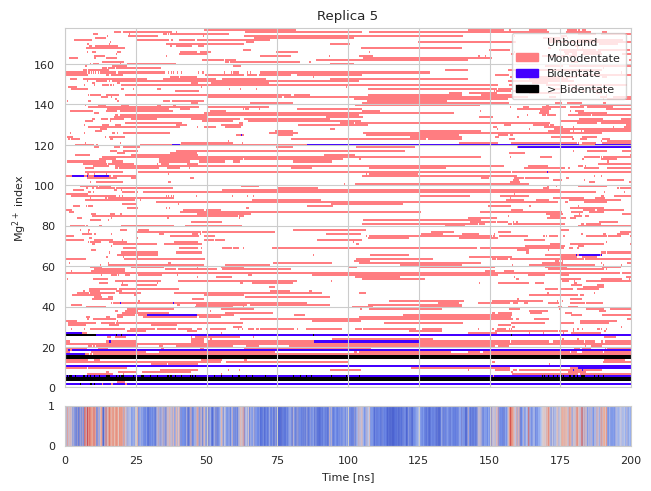

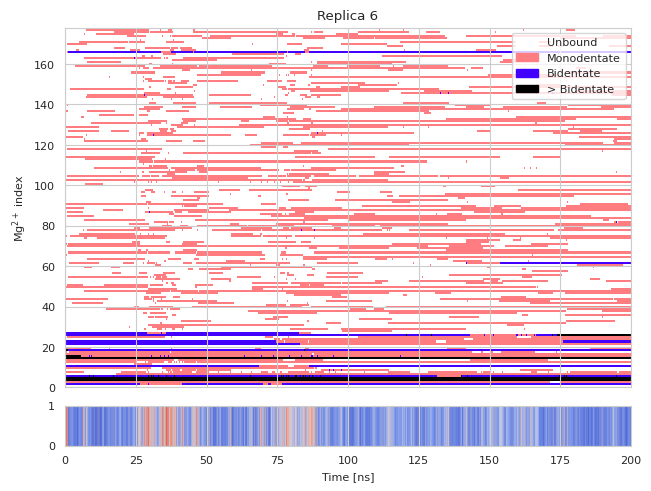

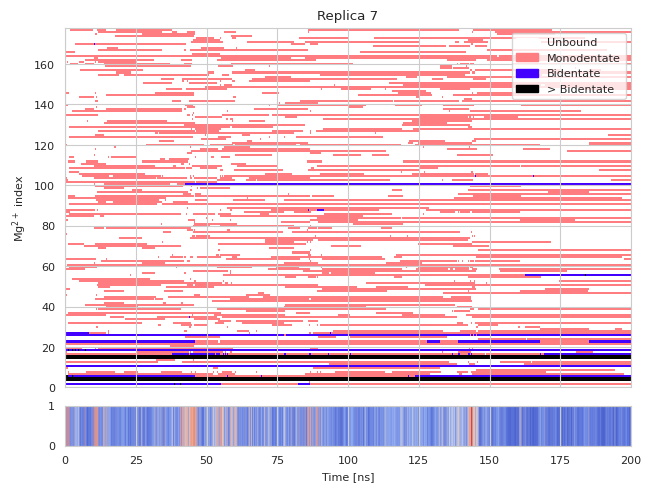

In [18]:
# New bound ions configurations found
figs = []
for k in range(nrep):
    dt = cv_dmx[k, 1, 0] / 1000 - cv_dmx[k, 0, 0] / 1000
    fig, axarr = plt.subplots(nrows=2, height_ratios=[0.9, 0.1], sharex=True)
    is_bound_mg = (nox_dmx[k, :, 1:-2:3] > 0.5) * 1 + (nox_dmx[k, :, 1:-2:3] > 1.5) * 1 + (nox_dmx[k, :, 1:-2:3] > 2.5) * 1
    from matplotlib.patches import Patch
    cmap = plt.cm.gnuplot2_r
    custom_patches = [Patch(color=cmap(0/3), label='Unbound'),
                    Patch(color=cmap(1/3), label='Monodentate'),
                    Patch(color=cmap(2/3), label='Bidentate'),
                    Patch(color=cmap(3/3), label='> Bidentate'),]
    ax = axarr[0]
    ax.imshow(is_bound_mg.T, origin='lower', extent=[0, len(is_bound_mg) / 10, 0, is_bound_mg.shape[1]], aspect='auto', cmap=cmap, interpolation='none')
    ax.set_ylabel(r"Mg$^{2+}$ index")
    ax.set_title(f"Replica {k}")
    ax.legend(handles=custom_patches)

    cmap = mpl.cm.coolwarm
    norm = mpl.colors.Normalize(0, nrep-1)
    ax = axarr[1]
    ax.imshow(cv_dmx[k, :, [-2]], cmap=plt.cm.coolwarm, vmin=0, vmax=nrep-1, origin='lower', extent=[*(cv_dmx[k, [0, -1], 0] / 1000), 0, 1], aspect='auto')
    ax.set_xlabel("Time [ns]")
    figs.append(fig)


with PdfPages(f'figures/replex/heatmap_mg_index_{system}_{ff}.pdf') as pdf:
    for fig in figs:
        pdf.savefig(fig, bbox_inches='tight') 

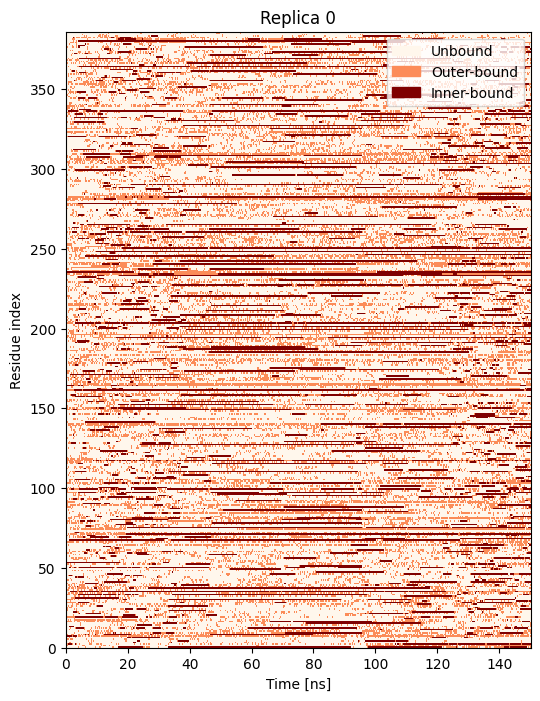

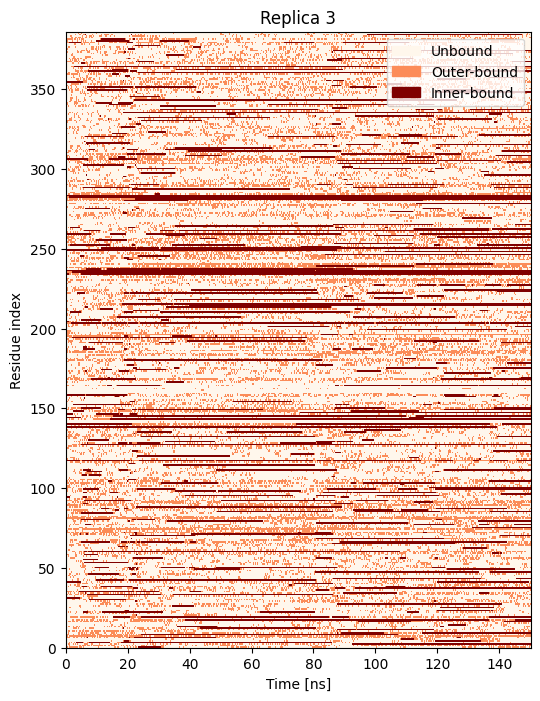

In [ ]:
# New bound ions configurations found
for k in [0, 3]:
    fig, ax = plt.subplots(figsize=(6, 8))
    # O1P or O2P
    is_bound_op = np.logical_or(d_op_mg_dmx[k, :, 1::2] < 0.25, d_op_mg_dmx[k, :, 2::2] < 0.25) * 1 + np.logical_or(d_op_mg_dmx[k, :, 1::2] < 0.42, d_op_mg_dmx[k, :, 2::2] < 0.42) * 1
    from matplotlib.patches import Patch
    cmap = plt.cm.OrRd
    custom_patches = [Patch(color=cmap(0.), label='Unbound'),
                    Patch(color=cmap(.5), label='Outer-bound'),
                    Patch(color=cmap(1.), label='Inner-bound')]
    ax.imshow(is_bound_op.T, origin='lower', extent=[0, len(is_bound_op)/10, 0, is_bound_op.shape[1]], aspect='auto', cmap=cmap, interpolation='none')
    ax.set_xlabel("Time [ns]")
    ax.set_ylabel(r"Residue index")
    ax.set_title(f"Replica {k}")
    ax.legend(handles=custom_patches)

Text(0, 0.5, '$ρ(d_\\mathrm{min})$')

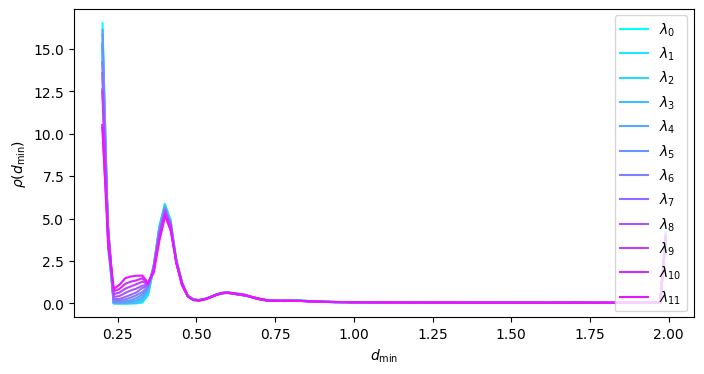

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for i in range(12):
    ρ_d, bins = np.histogram(d_mg_op[i, :, 1:].flatten(), bins=100, density=True)
    d_range = edges_to_range(bins)
    ax.plot(d_range, ρ_d, label=f'$λ_{{{i}}}$', color=plt.cm.cool(i/12.0))
ax.legend(loc='right')
ax.set_xlabel('$d_\mathrm{min}$')
ax.set_ylabel('$ρ(d_\mathrm{min})$')

(0.0, 1.0)

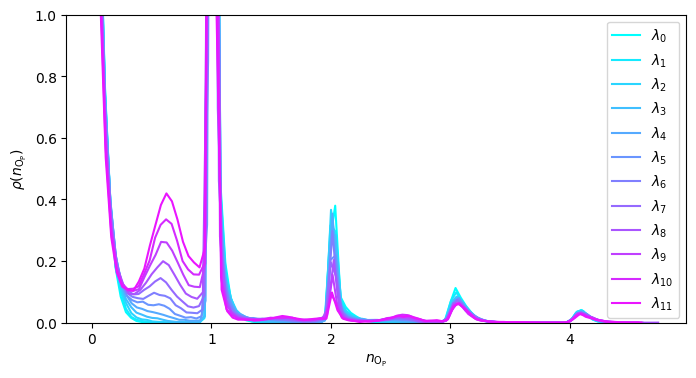

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for i in range(12):
    ρ_d, bins = np.histogram(nox[i, :, 1:-2:3].flatten(), bins=100, density=True)
    d_range = edges_to_range(bins)
    ax.plot(d_range, ρ_d, label=f'$λ_{{{i}}}$', color=plt.cm.cool(i/12.0))
ax.legend()
ax.set_xlabel('$n_\mathrm{O_P}$')
ax.set_ylabel('$ρ(n_\mathrm{O_P})$')
ax.set_ylim(0, 1)

Text(0, 0.5, '$ρ(n_\\mathrm{O_W})$')

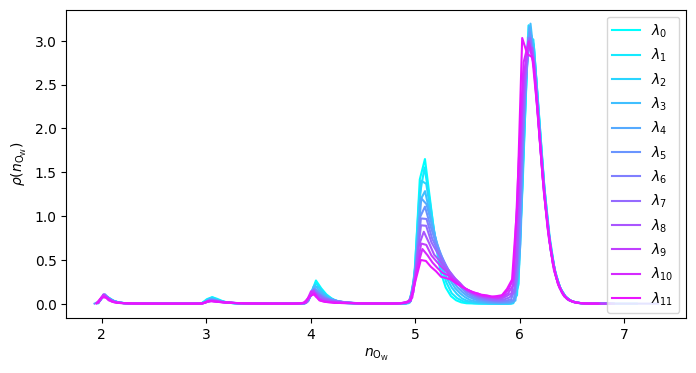

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for i in range(12):
    ρ_d, bins = np.histogram(nox[i, :, 2:-2:3].flatten(), bins=100, density=True)
    d_range = edges_to_range(bins)
    ax.plot(d_range, ρ_d, label=f'$λ_{{{i}}}$', color=plt.cm.cool(i/12.0))
ax.legend()
ax.set_xlabel('$n_\mathrm{O_W}$')
ax.set_ylabel('$ρ(n_\mathrm{O_W})$')

Text(0, 0.5, '$ρ(Δ(n_\\mathrm{O_P} - n_\\mathrm{O_W}))$')

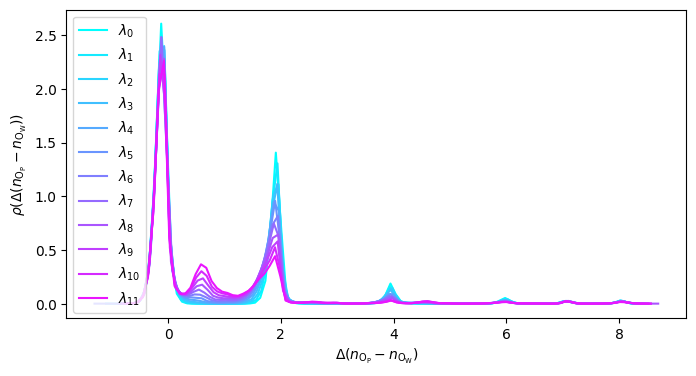

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for i in range(12):
    ρ_d, bins = np.histogram(nox[i, :, 1:-2:3].flatten() - nox[i, :, 2:-2:3].flatten() + 6, bins=100, density=True)
    d_range = edges_to_range(bins)
    ax.plot(d_range, ρ_d, label=f'$λ_{{{i}}}$', color=plt.cm.cool(i/12.0))
ax.legend()
ax.set_xlabel('$Δ(n_\mathrm{O_P} - n_\mathrm{O_W})$')
ax.set_ylabel('$ρ(Δ(n_\mathrm{O_P} - n_\mathrm{O_W}))$')

/scratch_local/ipykernel_2588483/1661913844.py:5: RuntimeWarning: divide by zero encountered in log
  ax.plot(d_range, -RT*np.log(ρ_d), label=f'$λ_{{{i}}}$', color=plt.cm.cool(i/12.0))


Text(0, 0.5, '$-RT\\ln ρ(Δ(n_\\mathrm{O_P} - n_\\mathrm{O_W}))$')

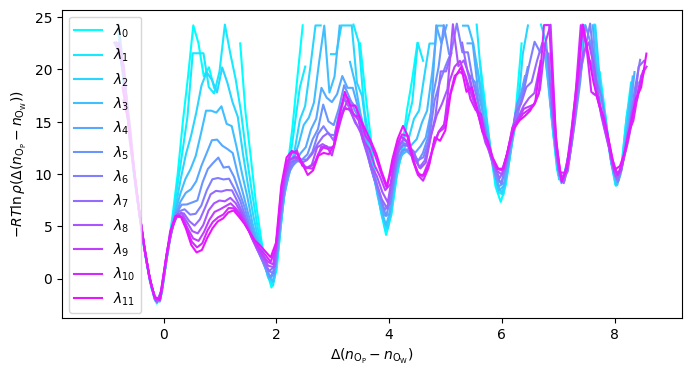

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for i in range(12):
    ρ_d, bins = np.histogram(nox[i, :, 1:-2:3].flatten() - nox[i, :, 2:-2:3].flatten() + 6, bins=100, density=True)
    d_range = edges_to_range(bins)
    ax.plot(d_range, -RT*np.log(ρ_d), label=f'$λ_{{{i}}}$', color=plt.cm.cool(i/12.0))
ax.legend()
ax.set_xlabel('$Δ(n_\mathrm{O_P} - n_\mathrm{O_W})$')
ax.set_ylabel('$-RT\ln ρ(Δ(n_\mathrm{O_P} - n_\mathrm{O_W}))$')

/scratch_local/ipykernel_2588483/3242777614.py:7: RuntimeWarning: divide by zero encountered in log
  cf = ax.contourf(x_range, y_range, -RT*np.log(ρ_d.T), cmap='magma_r', origin='lower', aspect=1, norm=norm)
/scratch_local/ipykernel_2588483/3242777614.py:7: UserWarning: The following kwargs were not used by contour: 'aspect'
  cf = ax.contourf(x_range, y_range, -RT*np.log(ρ_d.T), cmap='magma_r', origin='lower', aspect=1, norm=norm)


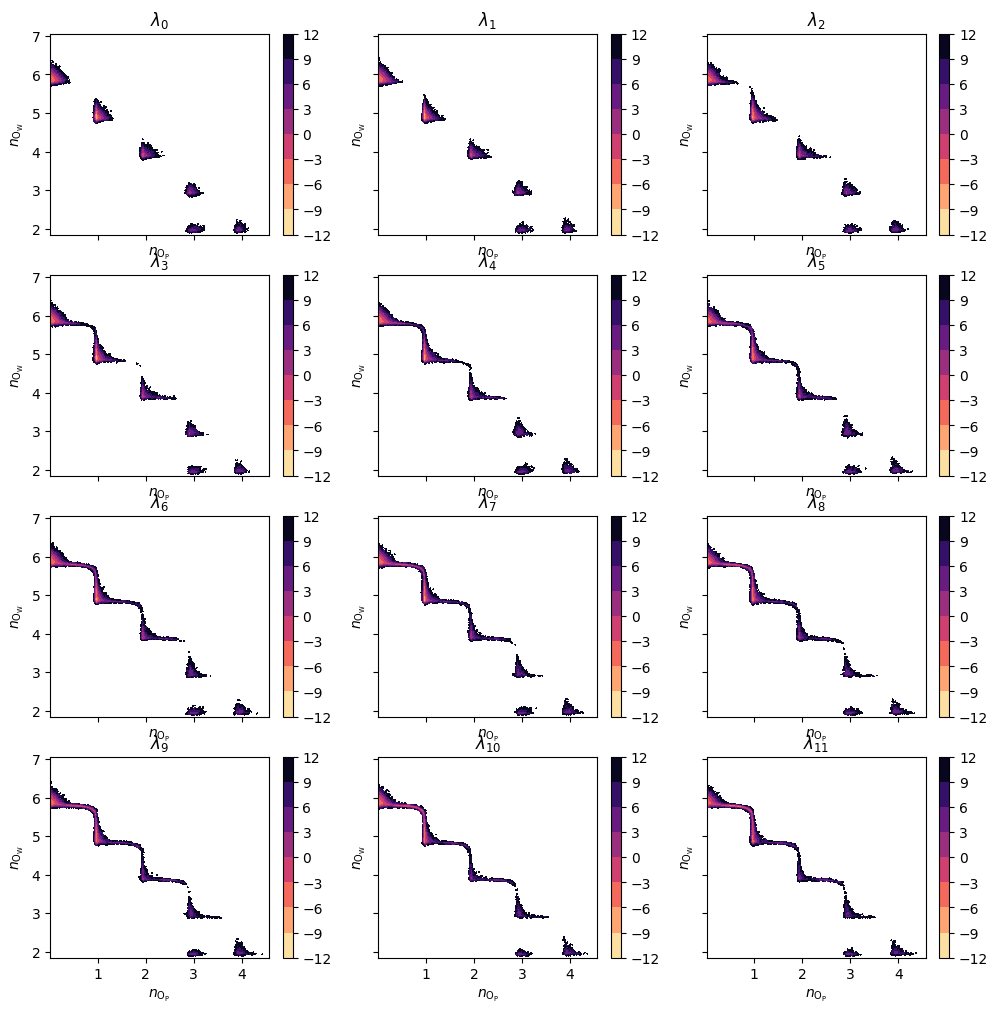

In [ ]:
import matplotlib as mpl
fig, axarr = plt.subplots(ncols=3, nrows=4, figsize=(12, 12), sharex=True, sharey=True)
norm = mpl.colors.Normalize()
for i, ax in enumerate(axarr.flatten()):
    ρ_d, x_edges, y_edges = np.histogram2d(nox[i, :, 1:-2:3].flatten(), nox[i, :, 2:-2:3].flatten(), bins=200, density=True)
    x_range, y_range = edges_to_range(x_edges), edges_to_range(y_edges)
    cf = ax.contourf(x_range, y_range, -RT*np.log(ρ_d.T), cmap='magma_r', origin='lower', aspect=1, norm=norm)
    ax.set_title(f'$λ_{{{i}}}$')
    ax.set_xlabel('$n_\mathrm{O_P}$')
    ax.set_ylabel('$n_\mathrm{O_W}$')
    plt.colorbar(cf)

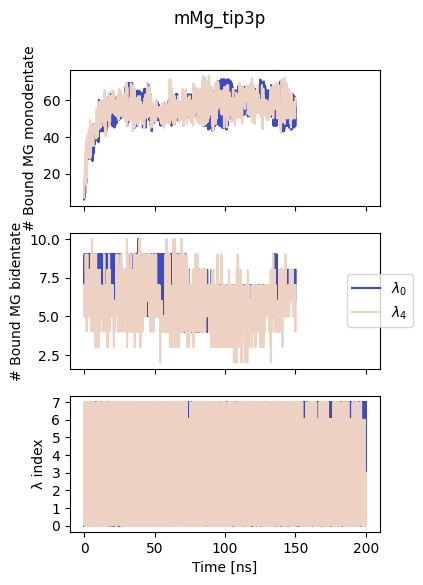

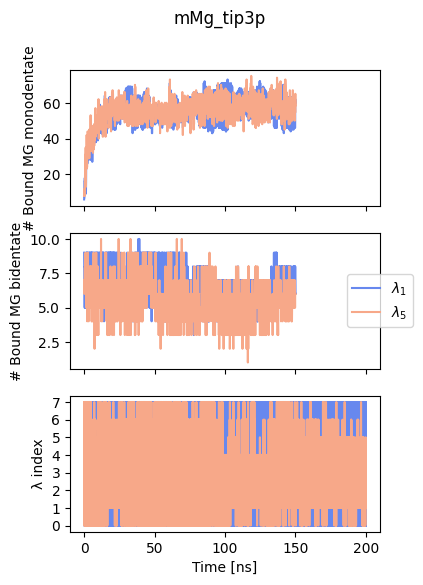

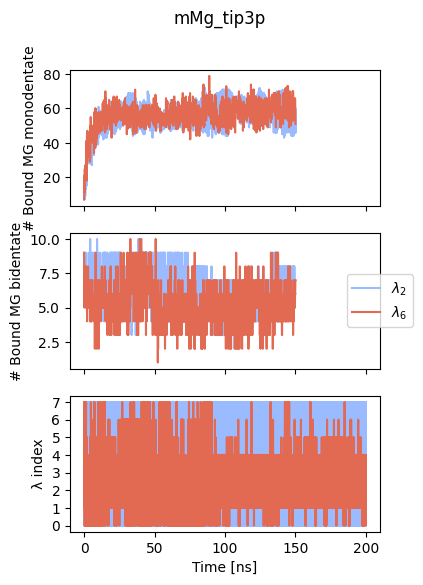

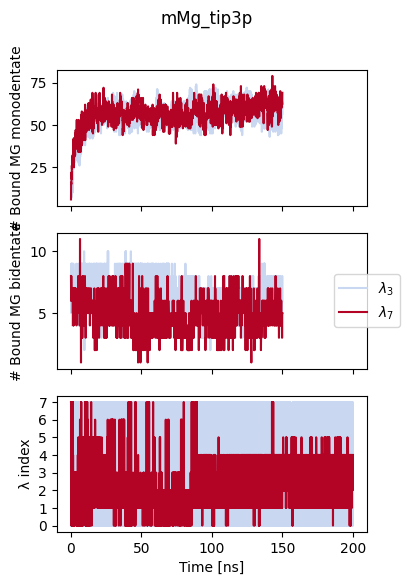

In [ ]:
figs = []
for n in range(4):
    fig, axarr = plt.subplots(nrows=3, sharex=True, figsize=(4, 6))
    fig.suptitle(ff)
    for i in range(n, nrep, 4):
        ax = axarr[0]
        is_mono = (nox[i, :, 1:-2:3] < 1.5) * (nox[i, :, 1:-2:3] > 0.5)
        is_bi = (nox[i, :, 1:-2:3] > 1.5) * (nox[i, :, 1:-2:3] < 2.5)
        ax.plot(nox[i, :, 0] / 1000, is_mono.sum(axis=-1), color=plt.cm.coolwarm(i/(nrep-1)), label=f'$λ_{{{i}}}$')
        ax.set_ylabel('# Bound MG monodentate')
        ax = axarr[1]
        ax.plot(nox[i, :, 0] / 1000, is_bi.sum(axis=-1), color=plt.cm.coolwarm(i/(nrep-1)), label=f'$λ_{{{i}}}$')
        ax.set_ylabel('# Bound MG bidentate')
        ax.legend(loc='center', bbox_to_anchor=(1, 0.5))
        ax = axarr[2]
        ax.plot(cv[i, :, 0] / 1000, cv[i, :, -1], color=plt.cm.coolwarm(i/(nrep-1)), label=f'$λ_{{{i}}}$')
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_ylabel('λ index')
        ax.set_xlabel("Time [ns]")
    figs.append(fig)

with PdfPages(f'figures/replex/bound_mg_denticity_{ff}.pdf') as pdf:
    for fig in figs:
        pdf.savefig(fig, bbox_inches='tight') 

Text(0, 0.5, '$ρ(n)$')

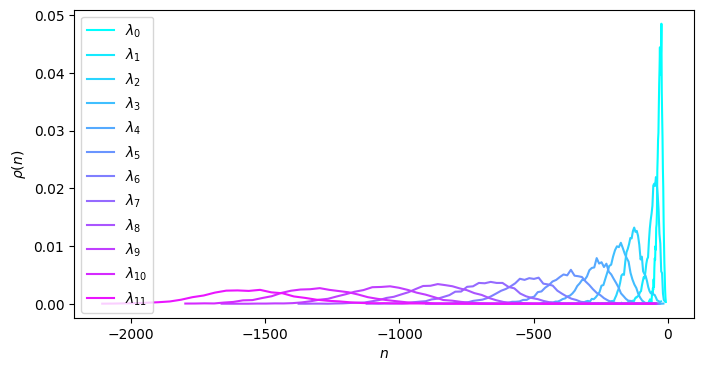

In [ ]:
# CV distribution as a function of λ
fig, ax = plt.subplots(figsize=(8, 4))
for i in range(0, 12):
    ρ_u, bins = np.histogram(cv[i, :, 1], bins=50, density=True)
    u_range = edges_to_range(bins)
    ax.plot(u_range, ρ_u, label=f'$λ_{{{i}}}$', color=plt.cm.cool(i/12.0))
ax.legend()
ax.set_xlabel('$n$')
ax.set_ylabel('$ρ(n)$')